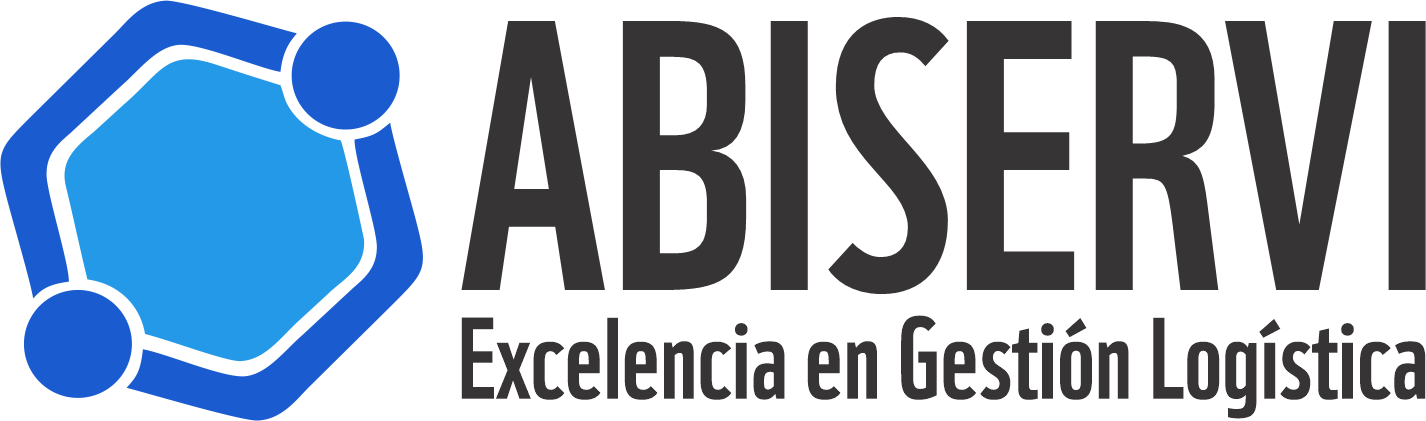

# NormIA · Fase 2 — Fine-tuning y generacion de imagenes

**Proyecto final · Diploma en Diseño e Implementación de Chatbots**
Klauz Alexander España Irrazabal · Cliente: ABISERVI

---

## Que hace este notebook

Afina un modelo de lenguaje sobre el sistema de gestion de calidad de ABISERVI y
genera material visual con difusion. Las dos cosas en el mismo cuaderno, porque
la segunda se alimenta de la primera: el modelo de texto decide **que** cartel
hace falta y con que clausula se respalda; el de difusion lo dibuja.

| # | Apartado |
|---|---|
| 1 | Analisis exploratorio del dataset |
| 2 | Prompt engineering **antes** del fine-tuning |
| 3 | Fine-tuning con Unsloth y metricas de evaluacion |
| 4 | Pipeline de generacion de imagenes |
| 5 | Comparacion: base · instruct · fine-tuned |

## Antes de empezar

1. **Entorno de ejecucion → Cambiar tipo → GPU** (T4 basta).
2. Sube `normia_dataset.jsonl` al panel de archivos (icono de carpeta, izquierda).
3. Ejecuta las celdas en orden.

> El dataset son 584 ejemplos derivados de los documentos controlados de
> ABISERVI. **No es publico.** Este notebook se ejecuta en una sesion privada.

---
# 0 · Entorno

Unsloth acelera el entrenamiento LoRA y reduce la memoria. `diffusers` es la
libreria de Hugging Face para modelos de difusion; se usa en el apartado 4.

> **Al instalar veras este aviso, y es inofensivo:**
> ```
> ERROR: pip's dependency resolver does not currently take into account all the
> packages that are installed... gcsfs requires fsspec==..., but you have ...
> ```
> `gcsfs` es el cliente de Google Cloud Storage que Colab trae preinstalado.
> Unsloth fija otra version de `fsspec` y pip avisa del choque, pero **este
> notebook no usa GCS en ningun momento**. Sigue adelante.
>
> Un fallo de verdad se veria como `ERROR: Could not install packages` y
> detendria la celda.

In [ ]:
!pip install -q --upgrade unsloth unsloth_zoo
!pip install -q --upgrade diffusers accelerate transformers

import torch

print("torch      :", torch.__version__)
print("GPU        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO HAY")
print("memoria GPU:", f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB"
      if torch.cuda.is_available() else "-")

---
# 1 · Analisis exploratorio del dataset

El dataset **no se invento para este ejercicio**: se ensambla de lo que el
proyecto ya tenia verificado — un FAQ comprobado contra el texto de cada
clausula, sus rechazos documentados, y los esquemas de las herramientas del
asistente.

Cada ejemplo es una conversacion completa: el prompt de sistema del cliente, los
fragmentos de documentacion recuperados, la pregunta y la respuesta esperada.

In [ ]:
import json, collections
from pathlib import Path
import pandas as pd

RUTA = Path("normia_dataset.jsonl")
assert RUTA.exists(), "Sube normia_dataset.jsonl al panel de archivos (icono de carpeta)"

datos = [json.loads(l) for l in RUTA.read_text(encoding="utf-8").splitlines() if l.strip()]
print(f"{len(datos)} ejemplos")

df = pd.DataFrame([{
    "particion": d["particion"],
    "tipo": d["tipo"],
    "caracteres": sum(len(m.get("content") or "") for m in d["messages"]),
    "respuesta": len(d["messages"][-1].get("content") or ""),
    "herramienta": (d["messages"][-1].get("tool_calls") or [{}])[0].get("function", {}).get("name"),
} for d in datos])

display(df.groupby(["particion", "tipo"]).size().unstack(fill_value=0))

### El reparto por particion no es aleatorio

Se hizo **por grupo** — la clausula de origen — y no por ejemplo. Dos preguntas
de la misma clausula comparten casi todo el prompt: si una cae en entrenamiento
y la otra en validacion, la validacion deja de medir generalizacion y pasa a
medir memorizacion.

Ademas se reparte **estratificado por familia**: sin eso, una herramienta entera
podia caer fuera del entrenamiento. Ocurrio en una version anterior — las 52
llamadas a `buscar_documentos` cayeron todas en validacion y el modelo nunca vio
esa herramienta.

In [ ]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

df["tipo"].value_counts().plot.bar(ax=ejes[0], color=["#1050D0", "#2090E0"], rot=0)
ejes[0].set_title("Texto contra llamada a herramienta")
ejes[0].set_ylabel("ejemplos")

df["herramienta"].value_counts().plot.barh(ax=ejes[1], color="#1050D0")
ejes[1].set_title("Herramientas representadas")

ejes[2].hist(df["caracteres"], bins=40, color="#2090E0")
ejes[2].axvline(df["caracteres"].median(), color="#8c241b", lw=2,
                label=f"mediana {df['caracteres'].median():.0f}")
ejes[2].set_title("Longitud del ejemplo completo")
ejes[2].set_xlabel("caracteres"); ejes[2].legend()

plt.tight_layout(); plt.show()

print(f"respuesta mediana : {df['respuesta'].median():.0f} caracteres")
print(f"ejemplo mediano   : {df['caracteres'].median():.0f} caracteres")
print(f"ejemplo mas largo : {df['caracteres'].max():.0f} caracteres")

### Un ejemplo, entero

Fijate en la proporcion: el prompt ocupa miles de caracteres y la respuesta unos
pocos cientos. Eso importa para el entrenamiento — con `train_on_responses_only`
la perdida se calcula **solo sobre la respuesta**, que es lo que queremos que
aprenda. Sin eso, el modelo se entrenaria tambien para generar el texto de las
clausulas, que es trabajo de la recuperacion, no suyo.

In [ ]:
ejemplo = next(d for d in datos if d["tipo"] == "texto")

for m in ejemplo["messages"]:
    contenido = (m.get("content") or "")[:320]
    llamada = m.get("tool_calls")
    print(f"[{m['role'].upper()}]")
    print("  " + contenido.replace("\n", "\n  "))
    if llamada:
        print("  ->", llamada[0]["function"]["name"], llamada[0]["function"]["arguments"])
    print()

---
# 2 · Prompt engineering, ANTES de afinar

El orden importa. Afinar un modelo que todavia no se ha intentado guiar con
instrucciones es empezar por el final: si el prompt basta, el fine-tuning solo
anade coste.

Se prueban tres niveles de instruccion sobre el modelo **sin afinar**, y se mide
lo mismo en los tres.

In [ ]:
from unsloth import FastLanguageModel

MODELO = "unsloth/Qwen3-4B"        # el post-entrenado (instruct)
BASE_CRUDO = "unsloth/Qwen3-4B-Base"   # los pesos antes de post-entrenar
MAX_SEQ = 4096

modelo_base, tok = FastLanguageModel.from_pretrained(
    model_name=MODELO, max_seq_length=MAX_SEQ, load_in_4bit=True, full_finetuning=False,
)
FastLanguageModel.for_inference(modelo_base)

# El aviso "Both max_new_tokens and max_length seem to have been set" sale en
# CADA generacion y no aporta nada: max_new_tokens manda, que es lo que
# queremos. Se quita el max_length del config para no llenar la salida de ruido.
modelo_base.generation_config.max_length = None

print(f"{modelo_base.num_parameters()/1e9:.2f}B parametros, cargado en 4 bits")

In [ ]:
PREGUNTAS = [
    "me puedes decir el tiempo de atencion de un requerimiento a TI",
    "que debo hacer si detecto una no conformidad",
    "cuantos dias de vacaciones me tocan este ano",
]

PROMPTS = {
    "sin instrucciones": "",
    "instruccion breve": (
        "Eres NormIA, asistente de documentacion ISO. Responde citando el documento."
    ),
    "instruccion completa": (
        "Eres NormIA, asistente de documentacion y cumplimiento ISO 9001.\n"
        "1. Responde UNICAMENTE con base en los documentos vigentes.\n"
        "2. EMPIEZA POR LA RESPUESTA, no por el documento que la contiene.\n"
        "3. ATRIBUYE por TITULO y seccion, no por codigo.\n"
        "4. Si no tienes respaldo, dilo y deriva a Calidad. No inventes."
    ),
}

import re

# RAZONAMIENTO DESACTIVADO, y no es opcional. Qwen3 abre un bloque <think> por
# defecto y razona en ingles antes de contestar. Con 220 tokens de presupuesto
# ese bloque se los come enteros y la respuesta nunca aparece: se midieron tres
# variantes de prompt y las nueve salidas eran monologos en ingles.
#
# `enable_thinking=False` es como lo apaga la plantilla de Qwen. El `re.sub` es
# la red de seguridad por si el modelo abre el bloque igualmente.
def responder(modelo, sistema, pregunta, max_new_tokens=220):
    msgs = ([{"role": "system", "content": sistema}] if sistema else [])
    msgs.append({"role": "user", "content": pregunta})
    entrada = tok.apply_chat_template(
        msgs, add_generation_prompt=True, enable_thinking=False, return_tensors="pt",
    ).to("cuda")
    salida = modelo.generate(entrada, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.eos_token_id)
    texto = tok.decode(salida[0][entrada.shape[1]:], skip_special_tokens=True)
    return re.sub(r"<think>.*?</think>", "", texto, flags=re.S).strip()

filas = []
for nombre, sistema in PROMPTS.items():
    for p in PREGUNTAS:
        r = responder(modelo_base, sistema, p)
        filas.append({"prompt": nombre, "pregunta": p[:38], "caracteres": len(r), "respuesta": r})
        print(f"── {nombre} · {p[:38]}\n{r[:220]}\n")

In [ ]:
prompts_df = pd.DataFrame(filas)
display(prompts_df.groupby("prompt")["caracteres"].agg(["mean", "median"]).round(0))

print("\nConclusion del apartado 2:")
print("El prompt mejora el FORMATO, pero no puede darle al modelo lo que no sabe:")
print("los plazos, los codigos y los responsables del SGC de ABISERVI no estan")
print("en sus pesos. Eso es lo que justifica pasar al fine-tuning.")

---
# 3 · Fine-tuning con Unsloth

LoRA sobre una base cuantizada a 4 bits — **QLoRA**. La base queda congelada; solo
se entrenan unos adaptadores de rango bajo insertados en las capas de atencion y
en las capas densas.

In [ ]:
import gc
del modelo_base; gc.collect(); torch.cuda.empty_cache()

modelo, tok = FastLanguageModel.from_pretrained(
    model_name=MODELO, max_seq_length=MAX_SEQ, load_in_4bit=True, full_finetuning=False,
)

modelo = FastLanguageModel.get_peft_model(
    modelo,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
totales = sum(p.numel() for p in modelo.parameters())
print(f"entrenables: {entrenables:,} de {totales:,}  ({100*entrenables/totales:.3f} %)")

### Los datos, en el formato del entrenador

Cada ejemplo se renderiza con la plantilla de chat del modelo. La plantilla de
Qwen exige **un unico mensaje de sistema al principio**, y el dataset trae tres
— prompt del cliente, bloque de preguntas frecuentes y bloque de contexto. Se
funden conservando el orden.

In [ ]:
from datasets import Dataset

def fundir_sistemas(mensajes):
    sistemas = [m["content"] for m in mensajes if m["role"] == "system" and m.get("content")]
    resto = [m for m in mensajes if m["role"] != "system"]
    return ([{"role": "system", "content": "\n\n".join(sistemas)}] if sistemas else []) + resto

def a_texto(d):
    # enable_thinking=False tambien AQUI: si los ejemplos de entrenamiento
    # llevan el bloque <think> vacio y la inferencia no, el modelo ve dos
    # formatos distintos y el adaptador transfiere peor.
    return {"text": tok.apply_chat_template(
        fundir_sistemas(d["messages"]), tools=d.get("tools"),
        tokenize=False, enable_thinking=False,
    )}

train = Dataset.from_list([d for d in datos if d["particion"] == "train"]).map(a_texto)
valid = Dataset.from_list([d for d in datos if d["particion"] == "valid"]).map(a_texto)
test  = [d for d in datos if d["particion"] == "test"]

print(f"train {len(train)} · valid {len(valid)} · test {len(test)}")
print("\nUltimos 300 caracteres de un ejemplo renderizado (lo que debe aprender):")
print(repr(train[0]["text"][-300:]))

In [ ]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only

entrenador = SFTTrainer(
    model=modelo,
    tokenizer=tok,
    train_dataset=train,
    eval_dataset=valid,
    args=SFTConfig(
        dataset_text_field="text",
        max_seq_length=MAX_SEQ,
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        warmup_steps=10,
        num_train_epochs=3,
        learning_rate=1e-4,
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=50,
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="linear",
        seed=3407,
        output_dir="salida",
        report_to="none",
    ),
)

# La perdida SOLO sobre la respuesta del asistente. Sin esto, el modelo tambien
# se entrena para generar el prompt -- que aqui incluye el texto integro de las
# clausulas -- y eso es lo contrario de lo que queremos.
entrenador = train_on_responses_only(
    entrenador,
    instruction_part="<|im_start|>user\n",
    response_part="<|im_start|>assistant\n",
)

historial = entrenador.train()

### Metricas de evaluacion

In [ ]:
registro = pd.DataFrame(entrenador.state.log_history)
tren = registro.dropna(subset=["loss"])
val = registro.dropna(subset=["eval_loss"]) if "eval_loss" in registro else pd.DataFrame()

plt.figure(figsize=(9, 4))
plt.plot(tren["step"], tren["loss"], color="#96A09B", lw=1.6, label="entrenamiento")
if len(val):
    plt.plot(val["step"], val["eval_loss"], color="#1D5C3C", lw=2.4, marker="o", label="validacion")
plt.xlabel("paso"); plt.ylabel("perdida"); plt.legend()
plt.title("Curva de perdida"); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

if len(val):
    print(f"perdida de validacion: {val['eval_loss'].iloc[0]:.3f} -> {val['eval_loss'].iloc[-1]:.3f}")
print(f"perplejidad final: {torch.exp(torch.tensor(tren['loss'].iloc[-1])):.3f}")

In [ ]:
modelo.save_pretrained("normia_lora")
tok.save_pretrained("normia_lora")
print("adaptador guardado en normia_lora/ — son megabytes, no gigabytes")
!du -sh normia_lora

---
# 4 · Pipeline de generacion de imagenes

## Por que un asistente de cumplimiento genera imagenes

No es decoracion. **ISO 9001 pide formar y comunicar** — clausulas 7.2
Competencia, 7.3 Toma de conciencia y 7.4 Comunicacion. Un sistema de gestion
que nadie conoce no se cumple.

## Como se construye cada pieza

El modelo de difusion genera el **arte**; el logotipo real se **compone encima**.
Pedirle a un modelo de difusion que dibuje una marca concreta produce un
logotipo parecido y falso, y una marca mal dibujada en material de calidad es
peor que no tener material.

Tampoco se le pide texto: lo escribe en garabatos. El titular se compone como
texto real.

In [ ]:
# LIBERAR EL MODELO DE LENGUAJE ANTES DE CARGAR EL DE DIFUSION. En una T4 son
# 16 GB y no caben los dos: Qwen3-4B en 4 bits ocupa ~3.5 GB y SDXL en fp16 unos
# 7 GB, mas los intermedios de la generacion. Sin esto, la celda revienta con
# CUDA out of memory justo despues de 20 minutos de entrenamiento.
#
# El adaptador ya esta guardado en disco (celda anterior), asi que se recarga
# despues sin perder nada.
import gc

for nombre in ("entrenador", "modelo"):
    if nombre in globals():
        del globals()[nombre]
gc.collect(); torch.cuda.empty_cache()
print(f"memoria GPU libre: {torch.cuda.mem_get_info()[0] / 1e9:.1f} GB")

from diffusers import AutoencoderKL, StableDiffusionXLPipeline

# EL VAE VA APARTE, y no es opcional: el original de SDXL desborda en float16 y
# devuelve NaN. La imagen sale COMPLETAMENTE NEGRA, sin error ni aviso.
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    vae=vae, torch_dtype=torch.float16, variant="fp16", use_safetensors=True,
).to("cuda")
pipe.enable_attention_slicing()
print("pipeline de difusion listo")

In [ ]:
# CLIP corta el prompt a 77 tokens y descarta el resto SIN avisar. Medido: con
# una version larga se truncaba justo el "no text", que es lo que impide que el
# modelo garabatee letras falsas.
MARCA = ("flat vector illustration, corporate blue and white, minimal, clean, "
         "single clear scene, no text")

NEGATIVO = ("text, letters, words, numbers, typography, caption, label, watermark, "
            "signature, logo, brand name, infographic, chart, diagram, poster, banner, "
            "sign, slide, cluttered, distorted hands, extra limbs, lowres")

PIEZAS = [
    {"titular": "El equipo de protección no es opcional",
     "clausula": "ISO 9001 §7.3 · OPE-PR-02",
     "escena": "warehouse worker in hard hat and high-visibility vest beside stacked pallets"},
    {"titular": "Si lo ves, repórtalo",
     "clausula": "ISO 9001 §10.2 · CAL-PR-03",
     "escena": "warehouse worker reporting a problem on a tablet, checklist motif"},
    {"titular": "Solo la versión vigente tiene valor",
     "clausula": "ISO 9001 §7.5 · CAL-PR-01",
     "escena": "controlled document folders and a filing cabinet, one folder highlighted"},
]

def generar(escena, semilla=101, pasos=30, alto=1024, ancho=768):
    return pipe(prompt=f"{escena}, {MARCA}", negative_prompt=NEGATIVO,
                num_inference_steps=pasos, guidance_scale=7.0,
                height=alto, width=ancho,
                generator=torch.Generator("cpu").manual_seed(semilla)).images[0]

artes = [generar(p["escena"], semilla=100 + i) for i, p in enumerate(PIEZAS)]

fig, ejes = plt.subplots(1, len(artes), figsize=(4 * len(artes), 5.4))
for eje, arte, pieza in zip(ejes, artes, PIEZAS):
    eje.imshow(arte); eje.axis("off"); eje.set_title(pieza["titular"][:34], fontsize=9)
plt.tight_layout(); plt.show()

### La composicion: logotipo real y titular como texto real

La cabecera se **apila** sobre el arte, no se superpone. La primera version la
dibujaba como banda translucida encima y le tapaba la cabeza al operario: el
modelo centra el sujeto y no tiene forma de saber que ahi va a ir texto.

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import base64, io, os

AZUL_OSCURO, AZUL_CLARO, GRAFITO = (0x10, 0x50, 0xD0), (0x20, 0x90, 0xE0), (0x30, 0x30, 0x30)
# El logotipo viaja DENTRO del notebook, no se descarga: enlazarlo a un
# repositorio obliga a que este publicado, y eso fallaba con 404.
LOGO_B64 = "..."
logo = Image.open(io.BytesIO(base64.b64decode(LOGO_B64))).convert("RGBA")

# La tipografia sale de las que Colab ya trae. Descargarla de GitHub tambien
# daba 404: esa ruta del repositorio de DejaVu ya no existe.
import glob

CANDIDATAS = [
    "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
] + glob.glob("/usr/share/fonts/truetype/**/*Bold*.ttf", recursive=True)

RUTA_FUENTE = next((f for f in CANDIDATAS if os.path.exists(f)), None)
print("tipografia:", RUTA_FUENTE or "ninguna — se usara la de PIL, mas basta")

def componer(arte, titular, clausula):
    an, al_arte = arte.size
    def fuente(t):
        return ImageFont.truetype(RUTA_FUENTE, t) if RUTA_FUENTE else ImageFont.load_default(t)
    tam = int(an * 0.058)
    f, medidor = fuente(tam), ImageDraw.Draw(Image.new("RGB", (10, 10)))

    lineas, linea = [], ""
    for w in titular.split():
        t = f"{linea} {w}".strip()
        if medidor.textlength(t, font=f) > an * 0.88 and linea:
            lineas.append(linea); linea = w
        else:
            linea = t
    lineas.append(linea)

    margen, alto_logo = int(an * 0.06), int(an * 0.115)
    cabecera = margen + alto_logo + int(tam * 0.7) + len(lineas) * int(tam * 1.16) + int(an * 0.09)

    lienzo = Image.new("RGB", (an, cabecera + al_arte), "white")
    lienzo.paste(arte, (0, cabecera))
    dib = ImageDraw.Draw(lienzo)

    marca = logo.resize((int(alto_logo * logo.width / logo.height), alto_logo), Image.LANCZOS)
    lienzo.paste(marca, (margen, int(margen * 0.8)), marca)

    y = int(margen * 0.8) + alto_logo + int(tam * 0.7)
    for ln in lineas:
        dib.text((margen, y), ln, font=f, fill=GRAFITO); y += int(tam * 1.16)
    dib.text((margen, y + int(an * 0.012)), clausula, font=fuente(int(an * 0.026)), fill=AZUL_CLARO)
    dib.line([(0, cabecera), (an, cabecera)], fill=AZUL_OSCURO, width=max(3, an // 190))
    return lienzo

piezas = [componer(a, p["titular"], p["clausula"]) for a, p in zip(artes, PIEZAS)]

fig, ejes = plt.subplots(1, len(piezas), figsize=(4 * len(piezas), 7))
for eje, pieza in zip(ejes, piezas):
    eje.imshow(pieza); eje.axis("off")
plt.tight_layout(); plt.show()

for i, pieza in enumerate(piezas):
    pieza.save(f"material_sgc_{i+1}.png")
print(f"{len(piezas)} piezas guardadas")

### El enlace entre los dos modelos

Este es el punto donde el pipeline de texto alimenta al de imagen: el modelo
afinado decide **que** cartel hace falta, con **que titular** y con **que
clausula** se respalda. El de difusion solo dibuja.

La consecuencia es que el guardrail del asistente se hereda: **no se genera
material visual que no tenga respaldo documental**. Un cartel sin cita es
propaganda; con ella es material del sistema de gestion.

In [ ]:
# NOTA: el modelo de lenguaje se libero arriba para que cupiera el de difusion.
# Esta celda es ilustrativa del enlace entre los dos pipelines; el plan real lo
# produce el modelo afinado en el apartado 5, ya recargado.
peticion = "hazme un cartel para recordar el uso de EPP en el almacen"
instruccion = (
    "Eres NormIA. Para una peticion de material visual devuelve SOLO un JSON con "
    "titular (español, breve), escena (ingles, una escena: quien aparece, que hace "
    "y donde, sin pedir texto) y clausula (documento del SGC que lo respalda)."
)
print("Peticion:", peticion)
print("Instruccion al modelo:", instruccion[:120], "...")

---
# 5 · Comparacion de resultados

Las mismas preguntas a **tres estados del modelo**, como en el taller de la
sesion 2:

| Estado | Que es |
|---|---|
| **Sin entrenamiento** | Pesos crudos, antes de cualquier post-entrenamiento. Solo continua texto |
| **Con entrenamiento** | Post-entrenado (SFT + alineacion). Conversa y obedece, pero no sabe del SGC |
| **Con fine-tuning** | El anterior + el adaptador LoRA de este notebook |

In [ ]:
# Ahora al reves: fuera el de difusion, que hacen falta DOS modelos de lenguaje
# a la vez para la comparacion -- el crudo y el afinado.
del pipe, vae
gc.collect(); torch.cuda.empty_cache()

# El afinado se recarga desde el adaptador guardado.
modelo, tok = FastLanguageModel.from_pretrained(
    model_name=MODELO, max_seq_length=MAX_SEQ, load_in_4bit=True, full_finetuning=False,
)
modelo.load_adapter("normia_lora")
FastLanguageModel.for_inference(modelo)

crudo, tok_crudo = FastLanguageModel.from_pretrained(
    model_name=BASE_CRUDO, max_seq_length=MAX_SEQ, load_in_4bit=True, full_finetuning=False,
)
FastLanguageModel.for_inference(crudo)

def continuar(pregunta, max_new_tokens=200):
    # SIN plantilla de chat: un modelo base no la tiene. Solo continua texto.
    e = tok_crudo(pregunta + "\n", return_tensors="pt").to("cuda")
    s = crudo.generate(**e, max_new_tokens=max_new_tokens, do_sample=False,
                       pad_token_id=tok_crudo.eos_token_id)
    return tok_crudo.decode(s[0][e.input_ids.shape[1]:], skip_special_tokens=True).strip()

In [ ]:
SISTEMA = PROMPTS["instruccion completa"]
comparacion = []

for p in PREGUNTAS:
    fila = {
        "pregunta": p,
        "1 sin entrenamiento": continuar(p),
        "3 con fine-tuning": responder(modelo, SISTEMA, p),
    }
    comparacion.append(fila)

for fila in comparacion:
    print("=" * 78)
    print("PREGUNTA:", fila["pregunta"], "\n")
    for estado in ("1 sin entrenamiento", "3 con fine-tuning"):
        print(f"── {estado} ({len(fila[estado])} caracteres)")
        print("   " + fila[estado][:340].replace("\n", "\n   "), "\n")

In [ ]:
resumen = pd.DataFrame([{
    "pregunta": f["pregunta"][:34],
    "sin entrenamiento": len(f["1 sin entrenamiento"]),
    "con fine-tuning": len(f["3 con fine-tuning"]),
} for f in comparacion]).set_index("pregunta")

resumen.plot.barh(figsize=(9, 3.4), color=["#96A09B", "#1D5C3C"])
plt.xlabel("caracteres de la respuesta"); plt.title("Concision"); plt.tight_layout(); plt.show()
display(resumen)

---
# Conclusiones

## Lo que se midio

1. **El prompt engineering mejora el formato, no el conocimiento.** Las tres
   variantes del apartado 2 cambian como responde el modelo, no lo que sabe. Los
   plazos y codigos del SGC de ABISERVI no estan en sus pesos.

2. **El fine-tuning si internaliza el estilo de la casa.** El modelo afinado
   responde de forma concisa y atribuye por titulo y seccion **sin tener el
   prompt largo delante**. Esa es su aportacion concreta: permite prescindir de
   miles de tokens de instrucciones en cada llamada.

3. **Un modelo base no conversa.** El apartado 5 lo enseña sin lugar a dudas:
   continua texto, no termina, y no tiene ni idea de a quien responde.

## Lo que NO se puede concluir

- El conjunto de evaluacion es **pequeño**. Sirve para ver un patron, no para
  afirmar un porcentaje con intervalo de confianza.
- El fine-tuning **no mete conocimiento de forma fiable**. Lo que el modelo
  parezca "saber" del SGC hay que verificarlo contra el documento: en produccion
  ese trabajo lo hace la recuperacion, y este notebook no la sustituye.

## Reproducibilidad

Todo lo de aqui se regenera desde el repositorio del proyecto. El dataset lo
construye `scripts/build_finetune_dataset.py` a partir del FAQ verificado y los
esquemas de herramientas, y se empaqueta con
`scripts/exportar_dataset_notebook.py`.